# Kryptonite response: manuscript figures

Reproduce Figures 1 and 2 from the saved results bundled in `data/`. No models are trained and no selection or test evaluation is performed. `data/evidence_manifest.json` records original paths and SHA-256 hashes. Use Python with numpy, matplotlib, and a working LaTeX/Times installation; run all cells in order. All plot text is 10.5 pt at a 6.75-inch insertion width. Figures are exported to `figures/`.

In [1]:
"""Reproduce both manuscript figures from saved results; no model training.

Dependencies: numpy, matplotlib, and a working LaTeX installation with Times.
The companion notebook contains these same cells and their executed outputs.
Run from this directory or the repository root.
"""
from pathlib import Path
import csv
import hashlib
import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

BASE = Path.cwd()
if not (BASE / "data" / "evidence_manifest.json").exists():
    BASE = BASE / "paper"
assert (BASE / "data" / "evidence_manifest.json").is_file()
FIGURES = BASE / "figures"
FIGURES.mkdir(exist_ok=True)


def records(name):
    with (BASE / "data" / name).open(newline="") as stream:
        return list(csv.DictReader(stream))


# Check that all included source tables are exact copies of the reviewed records.
manifest = json.loads((BASE / "data" / "evidence_manifest.json").read_text())
for item in manifest["source_records"]:
    assert hashlib.sha256((BASE / item["copy"]).read_bytes()).hexdigest() == item["sha256"]

# The ICML text width is 6.75 in. At that insertion width all figure text is
# 10.5 pt, slightly larger than the 10 pt manuscript. LaTeX embeds Type 1 fonts.
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": 10.5,
    "axes.labelsize": 10.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.6,
    "savefig.bbox": None,
    "savefig.dpi": 180,
})
BLUE, ORANGE, GREY = "#236192", "#C76B24", "#777777"

Matplotlib is building the font cache; this may take a moment.


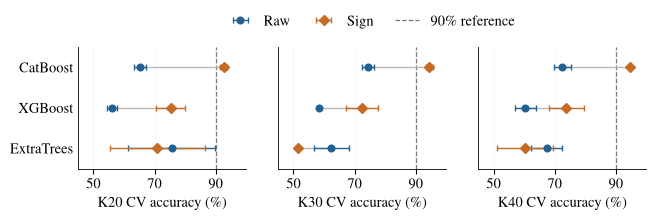

In [2]:
# Figure 1: paired raw/sign evaluation. Folds are inside the 70% training
# partition, not the outer 20% validation set. SD uses ddof=1 across 3 folds.
folds = records("representation_folds.csv")
summary = records("representation_summary.csv")
assert len(folds) == 90
methods = [("catboost", "CatBoost"), ("xgb", "XGBoost"), ("extra", "ExtraTrees")]
fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.25), sharey=True)
fig.subplots_adjust(left=.145, right=.987, bottom=.25, top=.79, wspace=.19)
for ax, dataset in zip(axes, ["20", "30", "40"]):
    ax.axvline(90, color=GREY, ls="--", lw=.9, zorder=1)
    for pos, (method, label) in zip([2, 1, 0], methods):
        values = {}
        for rep in ["raw", "sign"]:
            rows = sorted([r for r in folds if r["dataset"] == dataset
                           and r["method"] == method and r["representation"] == rep],
                          key=lambda r: int(r["fold"]))
            assert [int(r["fold"]) for r in rows] == [0,1,2]
            vals = 100 * np.array([float(r["accuracy"]) for r in rows])
            expected = next(r for r in summary if r["dataset"] == dataset and r["method"] == method)
            assert np.isclose(vals.mean(), 100 * float(expected[rep + "_mean_accuracy"]))
            values[rep] = (vals.mean(), vals.std(ddof=1))
        ax.plot([values["raw"][0], values["sign"][0]], [pos, pos], color="#BBBBBB", lw=1, zorder=2)
        for rep, color, marker in [("raw", BLUE, "o"), ("sign", ORANGE, "D")]:
            mean, sd = values[rep]
            ax.errorbar(mean, pos, xerr=sd, fmt=marker, ms=4.8, color=color,
                        capsize=2.2, elinewidth=1, lw=0, zorder=3,
                        label=rep.capitalize() if dataset == "20" and pos == 2 else None)
    ax.set_xlim(45, 100)
    ax.set_xticks([50, 70, 90])
    ax.set_ylim(-.5, 2.5)
    ax.set_yticks([2,1,0], [label for _,label in methods])
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel(r"K" + dataset + r" CV accuracy (\%)")
    ax.grid(axis="x", alpha=.13, lw=.5)
handles, labels = axes[0].get_legend_handles_labels()
reference = mpl.lines.Line2D([], [], ls="--", color=GREY, lw=.9)
fig.legend(handles + [reference], labels + [r"90\% reference"], loc="upper center",
           bbox_to_anchor=(.58, .99), ncol=3, frameon=False, handlelength=1.6,
           columnspacing=1.5)
fig.savefig(FIGURES / "representation.pdf")
fig.savefig(FIGURES / "representation.png")
plt.show()

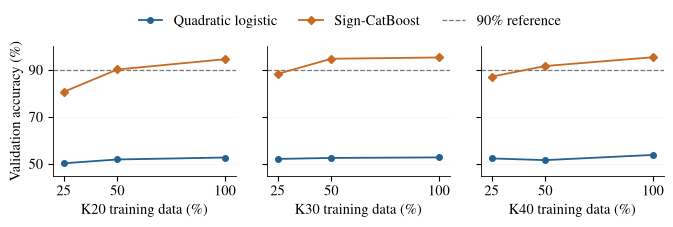

In [3]:
# Figure 2: the same nested training rows for both procedures and a common
# outer validation set. These are single fits, so no uncertainty bars are added.
baseline = records("baseline_runs.csv")
catboost = records("catboost_learning_curve.csv")
fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.35), sharey=True)
fig.subplots_adjust(left=.08, right=.985, bottom=.25, top=.8, wspace=.17)
for ax, dataset in zip(axes, ["20", "30", "40"]):
    a = sorted([r for r in baseline if r["dataset"] == dataset and r["method"] == "quadratic-logistic"],
               key=lambda r: int(r["training_percent"]))
    b = sorted([r for r in catboost if r["dataset"] == dataset], key=lambda r: int(r["training_percent"]))
    assert len(a) == len(b) == 3
    fractions = [int(r["training_percent"]) for r in a]
    assert fractions == [int(r["training_percent"]) for r in b] == [25, 50, 100]
    assert [int(r["training_size"]) for r in a] == [int(r["n_train"]) for r in b]
    ax.axhline(90, color=GREY, ls="--", lw=.9, label=r"90\% reference")
    ax.plot(fractions, [100 * float(r["validation_accuracy"]) for r in a],
            color=BLUE, marker="o", ms=4, lw=1.3, label="Quadratic logistic")
    ax.plot(fractions, [100 * float(r["validation_accuracy"]) for r in b],
            color=ORANGE, marker="D", ms=4, lw=1.3, label="Sign-CatBoost")
    ax.set_xlim(20,105)
    ax.set_ylim(45,100)
    ax.set_xticks([25,50,100])
    ax.set_yticks([50,70,90])
    ax.set_xlabel(r"K" + dataset + r" training data (\%)")
    ax.grid(axis="y", alpha=.15, lw=.5)
axes[0].set_ylabel(r"Validation accuracy (\%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend([handles[k] for k in [1,2,0]], [labels[k] for k in [1,2,0]],
           loc="upper center", bbox_to_anchor=(.52,.99), ncol=3, frameon=False,
           handlelength=1.6, columnspacing=1.5)
fig.savefig(FIGURES / "learning_curves.pdf")
fig.savefig(FIGURES / "learning_curves.png")
plt.show()

In [4]:
print("Both manuscript figures reproduced from hash-verified saved CSV records.")
for dataset in ["20", "30", "40"]:
    gains = []
    for source in [baseline, catboost]:
        rr = [r for r in source if r["dataset"] == dataset and
              r.get("method", "quadratic-logistic") == "quadratic-logistic"]
        acc = {int(r["training_percent"]): 100*float(r["validation_accuracy"]) for r in rr}
        gains.append(acc[100] - acc[25])
    print(f"K{dataset}: 25-to-100% gains = {gains[0]:.2f} pp (quadratic), {gains[1]:.2f} pp (sign-CatBoost).")

Both manuscript figures reproduced from hash-verified saved CSV records.
K20: 25-to-100% gains = 2.46 pp (quadratic), 13.92 pp (sign-CatBoost).
K30: 25-to-100% gains = 0.65 pp (quadratic), 7.03 pp (sign-CatBoost).
K40: 25-to-100% gains = 1.50 pp (quadratic), 8.27 pp (sign-CatBoost).
